## 20.1 Problem with Vanilla Seq2Seq

In a vanilla encoder–decoder Seq2Seq model, the encoder processes the entire input sequence and compresses it into **one fixed context vector**.

The decoder then has to generate the complete output sequence using that representation.

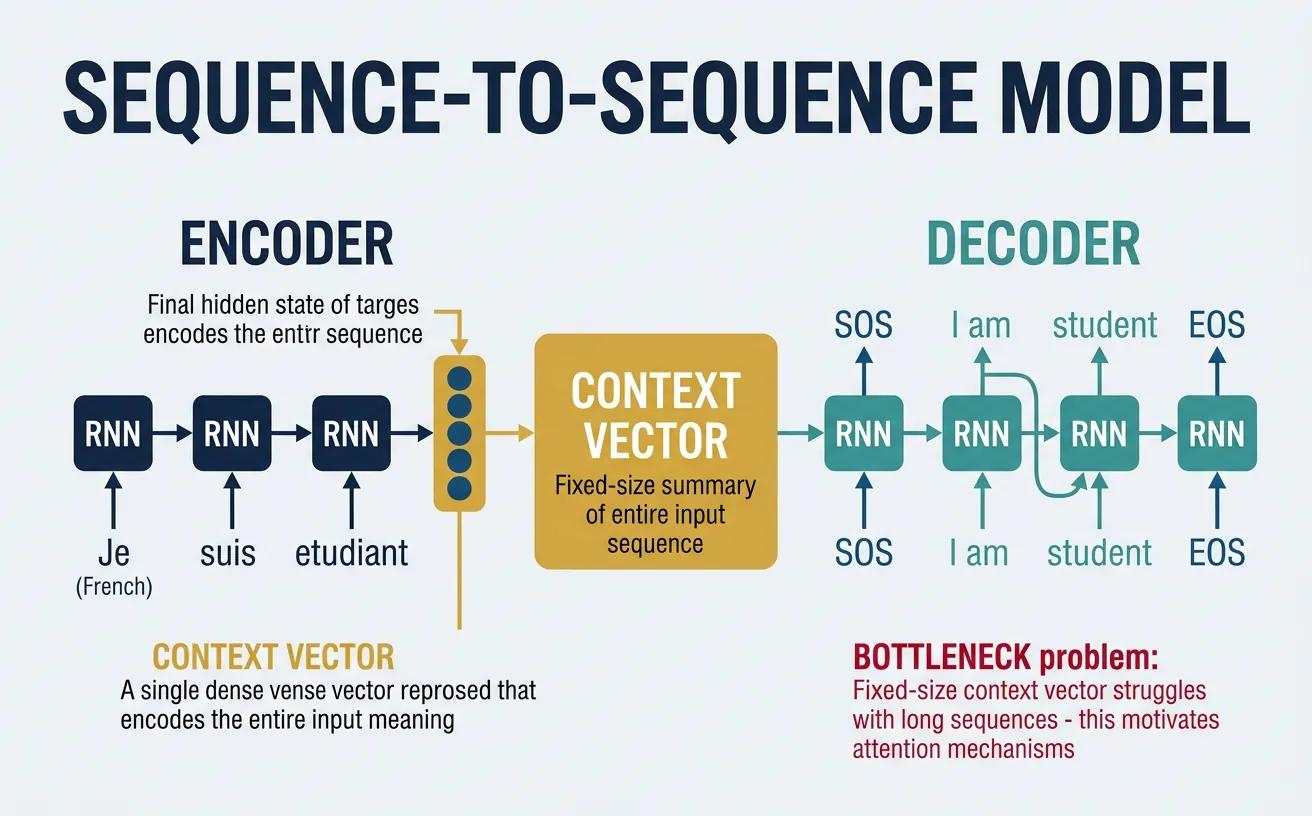

Conceptually:

$$
[x_1,x_2,\ldots,x_T
\rightarrow
\text{Encoder}
\rightarrow
\mathbf{c}
\rightarrow
\text{Decoder}
\rightarrow
y_1,y_2,\ldots,y_{T'}
]
$$

where

&&
[
\mathbf{c}
]
&&

is the **single context vector** representing the entire input.

This creates four important problems.

---

### 1. Long sequences

As the input sequence becomes longer, the encoder has to compress **more and more information into the same fixed-size representation**.

For example:

> "The boy who was sitting near the window picked up the red book that his teacher had given him yesterday."

The encoder needs to preserve information about:

- who did the action
- what the action was
- which object was involved
- relationships between words
- information appearing far apart

As sequence length increases, this becomes increasingly difficult.

**Key intuition:**

> More input information + same-size context vector → harder compression problem.

---

### 2. Information bottleneck

The fixed context vector acts as an **information bottleneck**.

Imagine:

```text
Input sequence
     │
     ▼
x₁ x₂ x₃ x₄ ... x₅₀
     │
     ▼
 ┌─────────┐
 │ Encoder │
 └─────────┘
     │
     ▼
   c
 (fixed)
     │
     ▼
 ┌─────────┐
 │ Decoder │
 └─────────┘
     │
     ▼
Output
```

The encoder must squeeze the information from potentially many tokens into one vector.

If important information is lost during this compression, **the decoder has no direct way to recover it**.

This is the fundamental bottleneck that attention addresses.

---

### 3. Fixed context vector

The decoder receives essentially the **same encoder-derived context representation** throughout generation.

Suppose the decoder is generating:

$$
\left[
y_1,\ y_2,\ y_3,\ \ldots
\right]
$$

Different output tokens may require different parts of the input.

For example:

```text
Input:
"The cat sat on the mat because it was tired."

                         ↓

Output generation:

"Le chat..."       → needs information about "cat"
"était..."         → may need information about "was"
"fatigué..."       → needs information about "tired"
```

A single fixed vector is not ideal because the decoder cannot dynamically ask:

> "Which part of the input is important for the word I am generating **right now**?"

That ability is precisely what attention introduces.

---

### 4. Difficult long-range dependencies

Vanilla Seq2Seq also struggles when relevant information occurs **far apart in the input sequence**.

For example:

> "The book that the student who studied NLP recommended was extremely useful."

To correctly interpret the sentence, the model needs to preserve relationships between words that may be separated by many other tokens.

The longer the sequence and the greater the distance between relevant information, the harder it becomes to preserve those dependencies through a single compressed representation.

---

## 🧠 The Core Problem

All four problems can be summarized as:

$$[
\boxed{
\text{Entire input sequence}
\rightarrow
\text{one fixed representation}
}
]
$$

That creates:

| Problem | What happens |
|---|---|
| **Long sequences** | More information must be compressed |
| **Information bottleneck** | Important information can be lost |
| **Fixed context vector** | Same representation is used during decoding |
| **Long-range dependencies** | Distant relationships become harder to preserve |

### The key question

Instead of forcing the decoder to rely on one fixed vector:

$$
[
\text{Input} \rightarrow \boxed{\mathbf{c}} \rightarrow \text{Decoder}
]
$$

what if the decoder could access **all encoder hidden states** and dynamically focus on the relevant ones?

$$[
\text{Encoder states}
\rightarrow
\boxed{\text{select relevant information}}
\rightarrow
\text{Decoder}
]
$$

💡 **That is the motivation for Attention.**

And this connects directly to what you already know from Deep Learning: rather than destroying information through a single fixed bottleneck, we allow the model to compute **data-dependent weights over representations**.

### What you should remember

1. Vanilla Seq2Seq compresses the entire input into a **fixed context vector**.
2. This creates an **information bottleneck**, especially for long sequences.
3. The decoder cannot dynamically access different parts of the input.
4. Long-range dependencies become difficult to preserve.
5. **Attention solves this by allowing the decoder to selectively use encoder information at each decoding step.**

---